# DSCI 552: HW4
- **Name:** Pavanitha Manche
- **USC ID:** 2866839249
- **GitHub Username:** Pavanitha09

## 1. Time Series Classification Part 1: Feature Creation/Extraction (from HW3)

In [85]:
import os
import re
import numpy as np
import pandas as pd
from scipy.stats import bootstrap

### 1(a) Data Loading

In [86]:
data_path = '../data/AReM/'
COLUMNS = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
ACTIVITIES = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

def read_instance(path):
    # Comment lines start with '#'; separators may be commas or spaces; drop any empty trailing column
    df = pd.read_csv(path, comment='#', header=None, names=range(8), sep=r'[,\s]+', engine='python')
    df = df.iloc[:, :7]
    df.columns = COLUMNS
    return df

def dataset_number(file_name):
    return int(re.search(r'\d+', file_name).group())

instances = []
for activity in ACTIVITIES:
    files = sorted(os.listdir(os.path.join(data_path, activity)), key=dataset_number)
    for file_name in files:
        instances.append({
            'activity': activity,
            'dataset': dataset_number(file_name),
            'data': read_instance(os.path.join(data_path, activity, file_name)),
        })

print(f"Loaded {len(instances)} instances")
display(pd.Series([inst['activity'] for inst in instances]).value_counts().rename('instances').to_frame())
display(instances[0]['data'].head())

Loaded 88 instances


,instances
cycling,15
lying,15
sitting,15
standing,15
walking,15
bending1,7
bending2,6


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


### 1(b) Train / Test Split

- **Test data:** datasets 1 and 2 from `bending1` and `bending2`, and datasets 1, 2 and 3 from every other folder.
- **Train data:** all remaining datasets.

In [87]:
def is_test(activity, dataset):
    if activity in ('bending1', 'bending2'):
        return dataset in (1, 2)
    return dataset in (1, 2, 3)

for inst in instances:
    inst['split'] = 'test' if is_test(inst['activity'], inst['dataset']) else 'train'

split_counts = pd.crosstab(
    pd.Series([inst['activity'] for inst in instances], name='activity'),
    pd.Series([inst['split'] for inst in instances], name='split'),
    margins=True,
)
display(split_counts)

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


### 1(c) Feature Extraction

#### i. Time-Domain Features Used in Time Series Classification


| # | Feature | Description |
| :-: | :-- | :-- |
| 1 | **Minimum** | The smallest value in the series. |
| 2 | **Maximum** | The largest value in the series. |
| 3 | **Mean** | The arithmetic average of all values; the typical level of the series. |
| 4 | **Median** | The middle value (50th percentile); less affected by outliers than the mean. |
| 5 | **Standard deviation** | How spread out the values are around the mean. |
| 6 | **First quartile (Q1)** | The 25th percentile; 25% of the values lie below it. |
| 7 | **Third quartile (Q3)** | The 75th percentile; 75% of the values lie below it. |
| 8 | **Interquartile range (IQR)** | Q3 − Q1; the spread of the middle 50% of the values. |
| 9 | **Skewness** | How asymmetric the distribution of values is (a longer tail on one side). |
| 10 | **Kurtosis** | How heavy the tails of the distribution are, i.e. how often extreme values occur. |
| 11 | **Auto-correlation** | The correlation between a series and a time-shifted (lagged) copy of itself; shows repeating patterns. |
| 12 | **Cross-correlation** | The correlation between two different series at various lags; shows how similar they are. |

#### ii. Extracting the Features



In [88]:
SERIES = COLUMNS[1:]
FEATURES = {
    'min': lambda s: s.min(),
    'max': lambda s: s.max(),
    'mean': lambda s: s.mean(),
    'median': lambda s: s.median(),
    'std': lambda s: s.std(),
    '1st_quart': lambda s: s.quantile(0.25),
    '3rd_quart': lambda s: s.quantile(0.75),
}

def extract_features(series_df):
    row = {}
    for i, col in enumerate(SERIES, start=1):
        for name, func in FEATURES.items():
            row[f'{name}{i}'] = func(series_df[col])
    return row

rows = []
for inst in instances:
    row = extract_features(inst['data'])
    row['activity'] = inst['activity']
    row['dataset'] = inst['dataset']
    row['split'] = inst['split']
    rows.append(row)

features_df = pd.DataFrame(rows)
features_df.index = pd.RangeIndex(1, len(features_df) + 1, name='Instance')
feature_cols = [c for c in features_df.columns if c not in ('activity', 'dataset', 'split')]

print(f"Feature table shape: {features_df.shape}  ({len(feature_cols)} features + activity, dataset, split)")
display(features_df)

Feature table shape: (88, 45)  (42 features + activity, dataset, split)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,dataset,split
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000,bending1,1,test
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000,bending1,2,test
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400,bending1,3,train
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000,bending1,4,train
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000,bending1,5,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,...,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225,walking,11,train
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,...,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650,walking,12,train
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,...,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350,walking,13,train


In [5]:
train_df = features_df[features_df['split'] == 'train']
test_df = features_df[features_df['split'] == 'test']
print(f"Train instances: {len(train_df)}, Test instances: {len(test_df)}")

Train instances: 69, Test instances: 19


#### iii. Standard Deviation of Each Feature and 90% Bootstrap Confidence Interval

In [89]:
def sample_std(x, axis=-1):
    return np.std(x, ddof=1, axis=axis)

ci_rows = []
for col in feature_cols:
    values = features_df[col].to_numpy()
    res = bootstrap((values,), sample_std, confidence_level=0.90, n_resamples=10000,
                    method='percentile', random_state=42)
    ci_rows.append({
        'Feature': col,
        'Std': sample_std(values),
        'CI Lower (5%)': res.confidence_interval.low,
        'CI Upper (95%)': res.confidence_interval.high,
    })

std_ci_df = pd.DataFrame(ci_rows).set_index('Feature')
pd.set_option('display.max_rows', 50)
display(std_ci_df.round(4))

,Std,CI Lower (5%),CI Upper (95%)
Feature,,,
min1,9.5700,8.2672,10.7818
max1,4.3944,3.3508,5.2999
mean1,5.3357,4.7043,5.8894
median1,5.4401,4.7869,6.0092
std1,1.7722,1.5651,1.9503
1st_quart1,6.1536,5.5543,6.6536
3rd_quart1,5.1389,4.3302,5.8448
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6221,5.4023


#### iv. Selecting the Three Most Important Features

**Chosen features: mean, standard deviation and maximum.**

- **Mean** - the typical level of a series. It separates the activities best on its own (posture in the `avg` series, amount of movement in the `var` series).
- **Standard deviation** - how much the series varies. It is the least correlated with the other features, so it adds information they do not have.
- **Maximum** - the strongest bursts of movement, which clearly distinguish walking and cycling from the still activities.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

In [90]:
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

In [91]:
SELECTED = ['mean', 'std', 'max']   # the three features chosen in 1(c)iv
L_VALUES = range(1, 21)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def build_features(l):
    rows = []
    for inst in instances:
        row = {'activity': inst['activity'], 'split': inst['split'],
               'bending': int(inst['activity'].startswith('bending'))}
        for p, idx in enumerate(np.array_split(np.arange(len(inst['data'])), l), start=1):
            part = inst['data'].iloc[idx]
            for i, col in enumerate(SERIES, start=1):
                for name in SELECTED:
                    row[f'{name}{i}' if l == 1 else f'{name}{i}_part{p}'] = FEATURES[name](part[col])
        rows.append(row)
    return pd.DataFrame(rows)

def xy(df, split, target='bending'):
    d = df[df['split'] == split]
    return d.drop(columns=['activity', 'split', 'bending']), d[target]

features_by_l = {l: build_features(l) for l in L_VALUES}

In [92]:
CLASS_NAMES = {0: 'other', 1: 'bending'}

def evaluate(model, X, y, title):
    # Accuracy, confusion matrix and ROC curve (one curve per class when there are more than 2 classes)
    pred, prob = model.predict(X), model.predict_proba(X)
    names = [CLASS_NAMES.get(c, c) for c in model.classes_]
    acc = accuracy_score(y, pred)
    if len(names) == 2:
        auc = roc_auc_score(y, prob[:, 1])
        curves = [('bending', y == 1, prob[:, 1])]
    else:
        auc = roc_auc_score(y, prob, multi_class='ovr')
        curves = [(name, y == cls, prob[:, k]) for k, (name, cls) in enumerate(zip(names, model.classes_))]

    print(f'{title}: accuracy = {acc:.4f}, error = {1 - acc:.4f}, AUC = {auc:.4f}')
    display(pd.DataFrame(confusion_matrix(y, pred, labels=model.classes_),
                         index=[f'true {n}' for n in names], columns=[f'pred {n}' for n in names]))
    for name, y_true, score in curves:
        fpr, tpr, _ = roc_curve(y_true, score)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_true, score):.3f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.title(f'ROC - {title}')
    plt.legend(fontsize=8)
    plt.show()
    return acc, auc

### 2(a) Binary Classification Using Logistic Regression

#### i. Scatter Plots of the Selected Features (Bending vs. Other Activities)

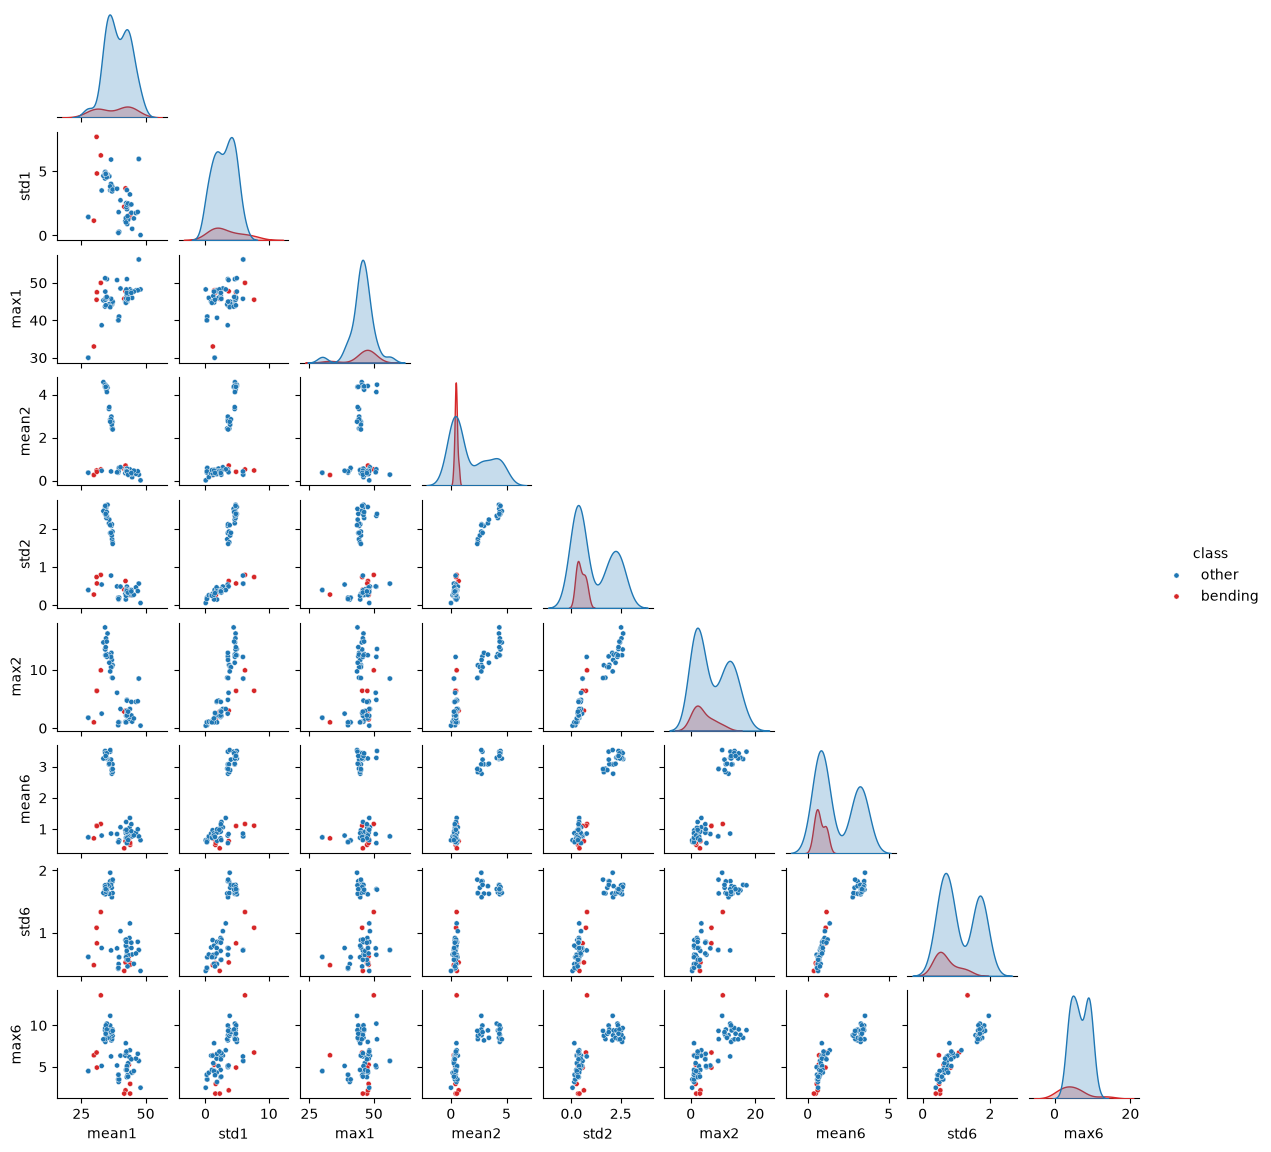

In [93]:
def scatter_matrix(l, series=(1, 2, 6)):
    df = features_by_l[l]
    df = df[df['split'] == 'train']
    cols = [f'{name}{i}' + ('' if l == 1 else f'_part{p}')
            for p in range(1, l + 1) for i in series for name in SELECTED]
    plot_df = df[cols].assign(**{'class': df['bending'].map(CLASS_NAMES)})
    g = sns.pairplot(plot_df, hue='class', hue_order=['other', 'bending'],
                     palette={'other': 'tab:blue', 'bending': 'tab:red'},
                     corner=True, height=1.3 if l == 1 else 1.0, plot_kws={'s': 14})
    plt.show()

scatter_matrix(l=1)

#### ii. Scatter Plots After Breaking Each Series Into Two Parts

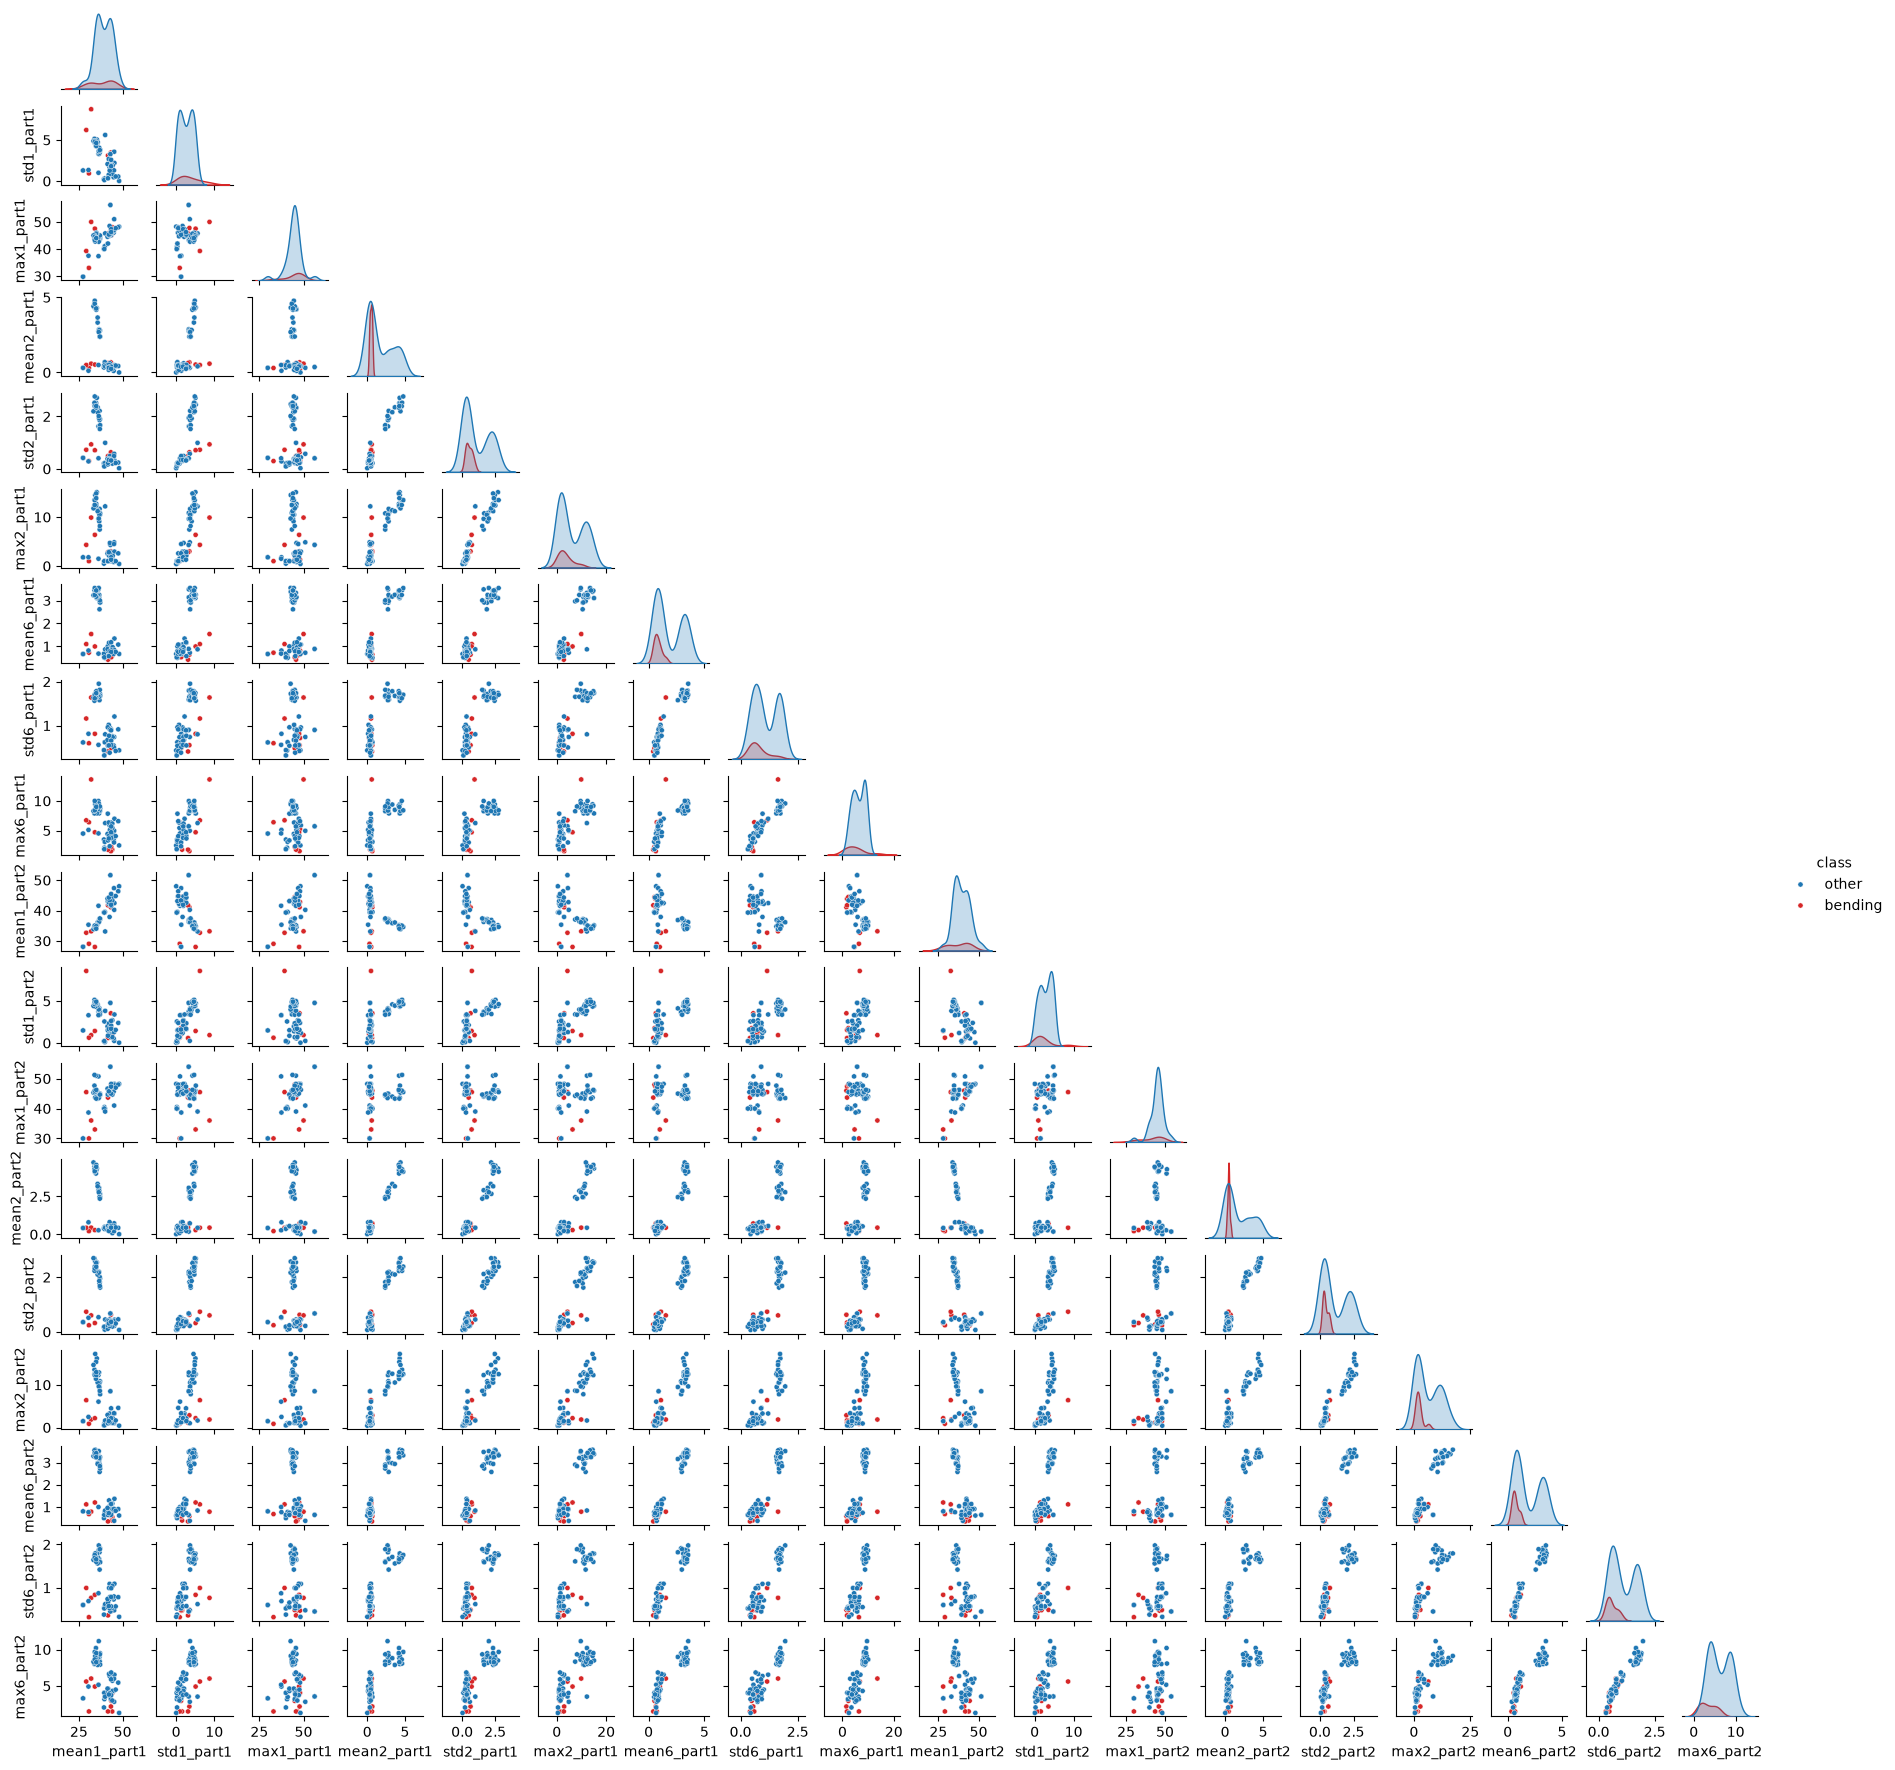

,mean1,std1,max1,mean2,std2,max2,mean6,std6,max6
"corr(part 1, part 2)",0.884,0.701,0.656,0.99,0.98,0.893,0.984,0.926,0.799


In [94]:
scatter_matrix(l=2)

# How similar are the features of the two halves?
d = features_by_l[2][features_by_l[2]['split'] == 'train']
display(pd.Series({f'{name}{i}': d[f'{name}{i}_part1'].corr(d[f'{name}{i}_part2'])
                   for i in (1, 2, 6) for name in SELECTED}, name='corr(part 1, part 2)').to_frame().T.round(3))

**Observations:**
* No considerable difference. Both halves show the same pattern as the full series in 2(a)i, because the features of the two halves are highly correlated (0.66 to 0.99).

#### iii. Choosing (l, p) with Recursive Feature Elimination and 5-Fold Stratified CV

* **Wrong way:** select the features (by p-values or RFE) on the whole training set first, and then cross-validate only the final model. The CV accuracy is too optimistic, because the held-out folds already helped choose the features.
* **Right way:** do the feature selection inside each fold, using only the training folds. `RFECV` does this, so it is used here.
* **Feature selection:** backward selection (RFE) is used instead of p-values, as the assignment allows.
* **Stratified CV:** keeps the same class proportions in every fold, so each fold gets some of the 9 bending instances. It is used here.

In [95]:
def rfe_logistic_regression(l):
    X, y = xy(features_by_l[l], 'train')
    pipe = Pipeline([('scale', StandardScaler()),
                     ('logreg', LogisticRegression(C=np.inf, max_iter=100))])
    rfecv = RFECV(pipe, step=1, cv=cv, scoring='accuracy',
                  importance_getter='named_steps.logreg.coef_')
    rfecv.fit(X, y)
    return rfecv.n_features_, rfecv.cv_results_['mean_test_score'].max()

rows = []
for l in L_VALUES:
    p, acc = rfe_logistic_regression(l)
    rows.append({'l': l, 'p (no. of features)': p, 'CV accuracy': acc, 'CV error': 1 - acc})

rfe_result = pd.DataFrame(rows).set_index('l')
display(rfe_result.round(4))

best_l = int(rfe_result['CV accuracy'].round(6).idxmax())   # smallest l on ties
best_p, rfe_cv_acc = int(rfe_result.loc[best_l, 'p (no. of features)']), rfe_result.loc[best_l, 'CV accuracy']
print(f'Best (l, p) = ({best_l}, {best_p}), CV accuracy = {rfe_cv_acc:.4f}')

,p (no. of features),CV accuracy,CV error
l,,,
1,3,0.9286,0.0714
2,21,0.9418,0.0582
3,1,0.9857,0.0143
4,1,0.9429,0.0571
5,44,0.9429,0.0571
6,7,0.9714,0.0286
7,1,0.9571,0.0429
8,13,0.9429,0.0571
9,8,0.9571,0.0429


Best (l, p) = (3, 1), CV accuracy = 0.9857


#### iv. Confusion Matrix, ROC and AUC on the Training Data; Coefficients and p-values

Selected features: ['mean5_part1']
RFE model, train data: accuracy = 0.9710, error = 0.0290, AUC = 0.9926


,pred other,pred bending
true other,59,1
true bending,1,8


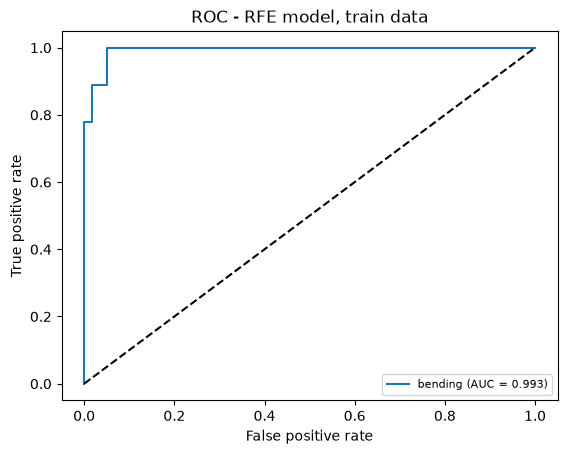

In [96]:
X_train, y_train = xy(features_by_l[best_l], 'train')
X_test, y_test = xy(features_by_l[best_l], 'test')

rfe_model = Pipeline([('scale', StandardScaler()),
                      ('rfe', RFE(LogisticRegression(C=np.inf, max_iter=100), n_features_to_select=best_p))])
rfe_model.fit(X_train, y_train)
selected = X_train.columns[rfe_model['rfe'].support_]
print('Selected features:', list(selected))

rfe_train_acc, rfe_train_auc = evaluate(rfe_model, X_train, y_train, 'RFE model, train data')

In [97]:
def wald_table(logreg, X_scaled, y, names):
    """Coefficients with Wald z-test p-values (standard errors from the inverse Fisher information)."""
    Xd = np.column_stack([np.ones(len(X_scaled)), X_scaled])
    beta = np.r_[logreg.intercept_, logreg.coef_.ravel()]
    prob = 1 / (1 + np.exp(-Xd @ beta))
    cov = np.linalg.pinv(Xd.T @ (Xd * (prob * (1 - prob))[:, None]))
    se = np.sqrt(np.diag(cov))
    z = beta / se
    return pd.DataFrame({'beta': beta, 'std. error': se, 'z': z, 'p-value': 2 * norm.sf(np.abs(z))},
                        index=['intercept'] + list(names))

X_train_sel = rfe_model['scale'].transform(X_train)[:, rfe_model['rfe'].support_]
display(wald_table(rfe_model['rfe'].estimator_, X_train_sel, y_train, selected).round(4))

,beta,std. error,z,p-value
intercept,-10.0560,7.0781,-1.4207,0.1554
mean5_part1,16.7156,12.7394,1.3121,0.1895


#### v. Test Set Results

RFE model, test data: accuracy = 0.8421, error = 0.1579, AUC = 0.9000


,pred other,pred bending
true other,13,2
true bending,1,3


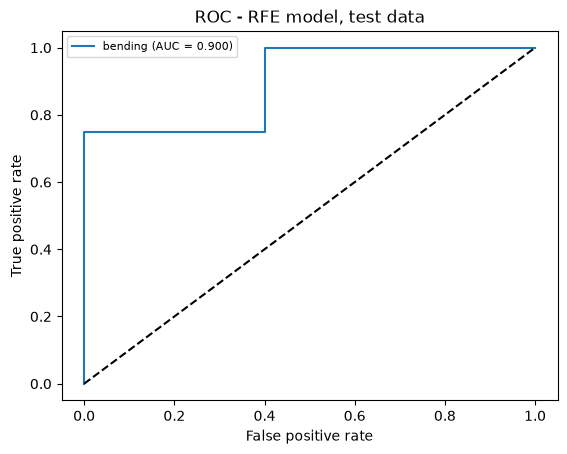

,Accuracy
5-fold CV (train),0.9857
Test set,0.8421


In [98]:
rfe_test_acc, rfe_test_auc = evaluate(rfe_model, X_test, y_test, 'RFE model, test data')

display(pd.DataFrame({'Accuracy': [rfe_cv_acc, rfe_test_acc]},
                     index=['5-fold CV (train)', 'Test set']).round(4))

**Observations:**
* The test accuracy (84.21%) is lower than the CV accuracy (98.57%). The CV accuracy is optimistic because it is the best of many (l, p) pairs, and the test set has only 19 instances (each error costs 5.3%).

#### vi. Separation

In [99]:
X_all, y_all = xy(features_by_l[1], 'train')
X_all = StandardScaler().fit_transform(X_all)

rows = []
for name, X_fit, y_fit in [(f'Selected feature (l={best_l}, p={best_p})', X_train_sel, y_train),
                           (f'All {X_all.shape[1]} features (l=1)', X_all, y_all)]:
    row = {'Model': name}
    for max_iter in [10, 100, 10000]:
        m = LogisticRegression(C=np.inf, max_iter=max_iter, tol=1e-10).fit(X_fit, y_fit)
        row[f'max |beta| (max_iter={max_iter})'] = round(np.abs(m.coef_).max(), 3)
    row['Train accuracy'] = round(m.score(X_fit, y_fit), 4)
    row['Train log-likelihood'] = -log_loss(y_fit, m.predict_proba(X_fit), normalize=False)
    rows.append(row)
display(pd.DataFrame(rows).set_index('Model'))

,max |beta| (max_iter=10),max |beta| (max_iter=100),max |beta| (max_iter=10000),Train accuracy,Train log-likelihood
Model,,,,,
"Selected feature (l=3, p=1)",12.332,16.928,16.928,0.971,-3.703129e+00
All 18 features (l=1),5.509,24.386,24.386,1.000,-8.014599e-09


* **Chosen model (1 feature): no.** The classes overlap (2 training errors), so a finite maximum-likelihood estimate exists: the coefficient converges to 16.93 and stays the same from `max_iter` = 100 to 10,000. (iv reports 16.72 because it uses the default, looser solver tolerance; the table uses `tol=1e-10`.)
* **More features (e.g. all 18 at l = 1): yes.** The classes are perfectly separated (100% training accuracy, log-likelihood ≈ 0), so no finite maximum-likelihood estimate exists and the coefficients depend only on when the solver stops (5.5 after 10 iterations, 24.4 after 100).

#### vii. Class Imbalance and Case-Control Sampling

In [100]:
display(pd.DataFrame({'Train': y_train.map(CLASS_NAMES).value_counts(),
                      'Test': y_test.map(CLASS_NAMES).value_counts()}))

,Train,Test
bending,,
other,60,15
bending,9,4


* **Yes, the classes are imbalanced:** 9 bending vs. 60 other in the training set, and 4 vs. 15 in the test set.
* **Case-control sampling:** keep all 9 bending instances, randomly sample 9 of the other instances, fit the logistic regression, and adjust the intercept:

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi}, \quad \pi = 9/69, \ \tilde\pi = 0.5$$

pi = 0.1304, pi_cc = 0.50
Intercept before adjustment = 9.1951, after = 7.2980, slope = 41.3120
case-control model, train data: accuracy = 0.9420, error = 0.0580, AUC = 0.9926


,pred other,pred bending
true other,56,4
true bending,0,9


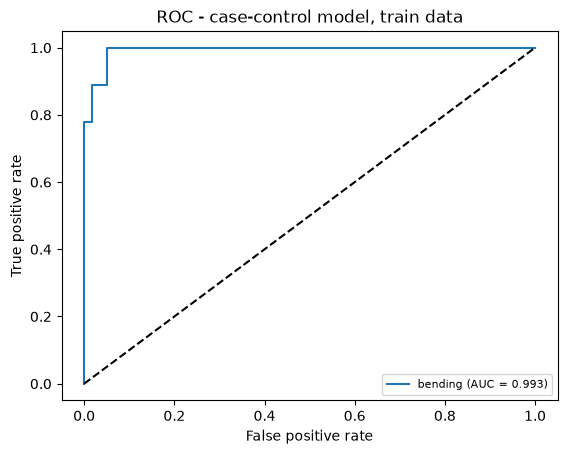

case-control model, test data: accuracy = 0.6842, error = 0.3158, AUC = 0.9000


,pred other,pred bending
true other,10,5
true bending,1,3


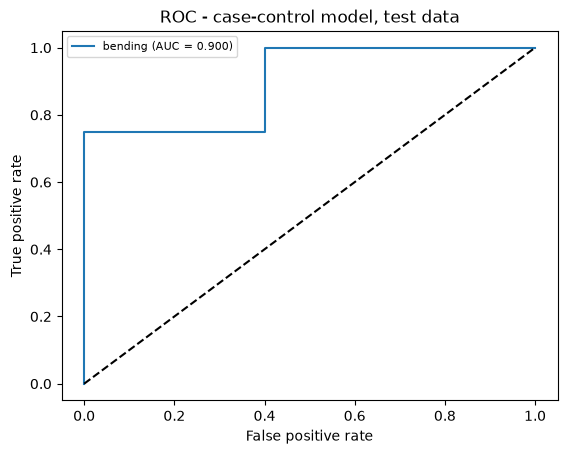

In [101]:
cases = X_train[y_train == 1]
controls = X_train[y_train == 0].sample(n=len(cases), random_state=42)
X_cc = pd.concat([cases, controls])[selected]
y_cc = y_train.loc[X_cc.index]

cc_model = Pipeline([('scale', StandardScaler()),
                     ('logreg', LogisticRegression(C=np.inf, max_iter=100))])
cc_model.fit(X_cc, y_cc)

pi, pi_cc = y_train.mean(), y_cc.mean()
b0 = cc_model['logreg'].intercept_[0]
cc_model['logreg'].intercept_ = cc_model['logreg'].intercept_ + np.log(pi / (1 - pi)) - np.log(pi_cc / (1 - pi_cc))
print(f'pi = {pi:.4f}, pi_cc = {pi_cc:.2f}')
print(f'Intercept before adjustment = {b0:.4f}, after = {cc_model["logreg"].intercept_[0]:.4f}, '
      f'slope = {cc_model["logreg"].coef_[0, 0]:.4f}')

cc_train_acc, cc_train_auc = evaluate(cc_model, X_train[selected], y_train, 'case-control model, train data')
cc_test_acc, cc_test_auc = evaluate(cc_model, X_test[selected], y_test, 'case-control model, test data')

### 2(b) Binary Classification Using L1-Penalized Logistic Regression

#### i. Choosing (l, C) with 5-Fold Stratified CV

In [102]:
C_GRID = np.logspace(-2, 2, 9)

def l1_logreg(C=1.0, solver='liblinear'):
    return Pipeline([('scale', StandardScaler()),
                     ('logreg', LogisticRegression(C=C, l1_ratio=1, solver=solver, max_iter=5000, random_state=42))])

rows = []
for l in L_VALUES:
    X, y = xy(features_by_l[l], 'train')
    gs = GridSearchCV(l1_logreg(), {'logreg__C': C_GRID}, cv=cv, scoring='accuracy')
    gs.fit(X, y)
    rows.append({'l': l, 'best C': gs.best_params_['logreg__C'], 'CV accuracy': round(gs.best_score_, 6),
                 'non-zero features': int((gs.best_estimator_['logreg'].coef_ != 0).sum()),
                 'total features': X.shape[1]})

l1_grid = pd.DataFrame(rows).set_index('l')
display(l1_grid.round(4).astype(object).T)

best = l1_grid.reset_index().sort_values(['CV accuracy', 'non-zero features', 'l'], ascending=[False, True, True]).iloc[0]
l1_l, l1_C, l1_cv_acc = int(best['l']), best['best C'], best['CV accuracy']
print(f'Best (l, C) = ({l1_l}, {l1_C:.4g}), CV accuracy = {l1_cv_acc:.4f}')

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best C,3.1623,0.3162,0.3162,0.3162,1.0,0.3162,0.3162,0.3162,0.3162,3.1623,1.0,1.0,1.0,0.3162,0.3162,1.0,1.0,1.0,1.0,1.0
CV accuracy,0.9714,0.9571,0.9714,0.9571,0.9418,0.9571,0.9418,0.9286,0.9132,0.9571,0.9571,0.9857,0.9571,0.9714,0.9571,0.9429,0.9571,0.9857,0.9857,0.9857
non-zero features,7,4,3,7,11,5,7,9,8,15,8,5,7,6,8,8,10,11,8,7
total features,18,36,54,72,90,108,126,144,162,180,198,216,234,252,270,288,306,324,342,360


Best (l, C) = (12, 1), CV accuracy = 0.9857


Non-zero coefficients (5 of 216):


,beta
mean5_part2,2.3326
std3_part3,0.0830
max1_part7,-0.6467
mean5_part11,0.2930
max6_part11,-0.6701


L1 model, train data: accuracy = 1.0000, error = 0.0000, AUC = 1.0000


,pred other,pred bending
true other,60,0
true bending,0,9


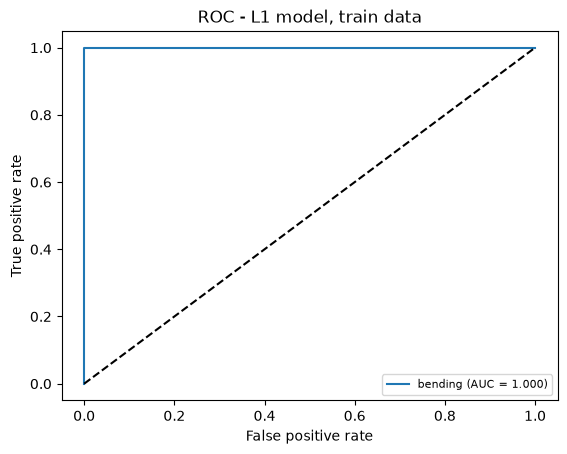

L1 model, test data: accuracy = 0.9474, error = 0.0526, AUC = 0.9833


,pred other,pred bending
true other,15,0
true bending,1,3


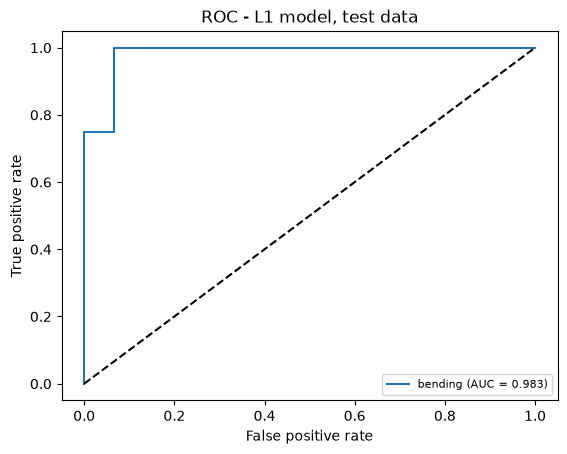

In [103]:
X_train_l1, y_train_l1 = xy(features_by_l[l1_l], 'train')
X_test_l1, y_test_l1 = xy(features_by_l[l1_l], 'test')

l1_model = l1_logreg(C=l1_C).fit(X_train_l1, y_train_l1)
coefs = pd.Series(l1_model['logreg'].coef_.ravel(), index=X_train_l1.columns)
print(f'Non-zero coefficients ({(coefs != 0).sum()} of {len(coefs)}):')
display(coefs[coefs != 0].to_frame('beta').round(4))

l1_train_acc, l1_train_auc = evaluate(l1_model, X_train_l1, y_train_l1, 'L1 model, train data')
l1_test_acc, l1_test_auc = evaluate(l1_model, X_test_l1, y_test_l1, 'L1 model, test data')

#### ii. L1 Penalty vs. Variable Selection with p-values/RFE

In [104]:
display(pd.DataFrame({
    'Best l': [best_l, l1_l],
    'Features used': [best_p, int((coefs != 0).sum())],
    'CV accuracy': [rfe_cv_acc, l1_cv_acc],
    'Test accuracy': [rfe_test_acc, l1_test_acc],
    'Test AUC': [rfe_test_auc, l1_test_auc],
}, index=['RFE (backward selection)', 'L1-penalized']).round(4))

,Best l,Features used,CV accuracy,Test accuracy,Test AUC
RFE (backward selection),3,1,0.9857,0.8421,0.9000
L1-penalized,12,5,0.9857,0.9474,0.9833


* **Performance:** L1-penalized logistic regression performs better on the test set (accuracy 94.74% vs. 84.21%, AUC 0.9833 vs. 0.9000). Both have the same CV accuracy (98.57%).
* **Implementation:** L1 is easier. Feature selection happens in one fit, only (l, C) has to be cross-validated, and no p-values are needed.

### 2(c) Multi-class Classification (The Realistic Case)

#### i. L1-Penalized Multinomial Regression

* **Multiclass confusion matrix:** a K × K table where entry (i, j) counts the instances of true class i predicted as class j.
* **Multiclass ROC (one-vs-rest):** one ROC curve per class (that class vs. all others), summarized by the average AUC.

In [105]:
rows = []
for l in L_VALUES:
    X, y = xy(features_by_l[l], 'train', target='activity')
    gs = GridSearchCV(l1_logreg(solver='saga'), {'logreg__C': C_GRID}, cv=cv, scoring='accuracy', n_jobs=-1)
    gs.fit(X, y)
    used = (gs.best_estimator_['logreg'].coef_ != 0).any(axis=0).sum()
    rows.append({'l': l, 'best C': gs.best_params_['logreg__C'], 'CV accuracy': round(gs.best_score_, 6),
                 'non-zero features': int(used), 'total features': X.shape[1]})

multi_grid = pd.DataFrame(rows).set_index('l')
display(multi_grid.round(4).astype(object).T)

best = multi_grid.reset_index().sort_values(['CV accuracy', 'non-zero features', 'l'], ascending=[False, True, True]).iloc[0]
multi_l, multi_C, multi_cv_acc = int(best['l']), best['best C'], best['CV accuracy']
print(f'Best (l, C) = ({multi_l}, {multi_C:.4g}), CV accuracy = {multi_cv_acc:.4f}')

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best C,1.0,0.3162,0.3162,3.1623,100.0,100.0,3.1623,100.0,100.0,10.0,100.0,3.1623,100.0,100.0,10.0,1.0,1.0,3.1623,100.0,10.0
CV accuracy,0.8989,0.8264,0.8264,0.8418,0.8571,0.8571,0.856,0.7846,0.8571,0.8132,0.8429,0.8143,0.8286,0.756,0.8714,0.8143,0.8857,0.8418,0.8132,0.8286
non-zero features,12,18,22,36,90,108,53,144,162,100,198,63,234,251,141,59,66,99,334,186
total features,18,36,54,72,90,108,126,144,162,180,198,216,234,252,270,288,306,324,342,360


Best (l, C) = (1, 1), CV accuracy = 0.8989


L1 multinomial, test data: accuracy = 0.9474, error = 0.0526, AUC = 0.9911


,pred bending1,pred bending2,pred cycling,pred lying,pred sitting,pred standing,pred walking
true bending1,2,0,0,0,0,0,0
true bending2,0,2,0,0,0,0,0
true cycling,0,0,3,0,0,0,0
true lying,0,0,0,3,0,0,0
true sitting,0,0,0,0,3,0,0
true standing,0,0,0,0,1,2,0
true walking,0,0,0,0,0,0,3


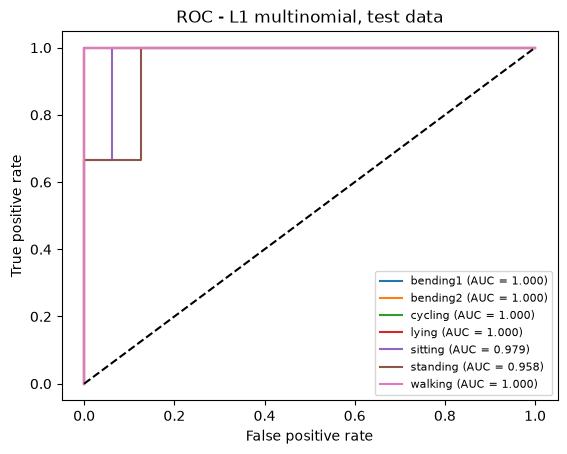

In [106]:
X_train_m, y_train_m = xy(features_by_l[multi_l], 'train', target='activity')
X_test_m, y_test_m = xy(features_by_l[multi_l], 'test', target='activity')

multi_model = l1_logreg(C=multi_C, solver='saga').fit(X_train_m, y_train_m)
multi_test_acc, multi_test_auc = evaluate(multi_model, X_test_m, y_test_m, 'L1 multinomial, test data')

#### ii. Naive Bayes Classifier (Gaussian and Multinomial)

In [107]:
nb_results = {}
for name, nb_model in [('Gaussian NB', GaussianNB()), ('Multinomial NB', MultinomialNB())]:
    cv_acc = []
    for l in L_VALUES:
        X, y = xy(features_by_l[l], 'train', target='activity')
        cv_acc.append(cross_val_score(nb_model, X, y, cv=cv, scoring='accuracy').mean())
    nb_results[name] = pd.Series(cv_acc, index=pd.Index(L_VALUES, name='l'))

nb_grid = pd.DataFrame(nb_results)
display(nb_grid.T.round(4))

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Gaussian NB,0.8857,0.8560,0.8418,0.8560,0.8275,0.8560,0.8132,0.7989,0.7692,0.7549,0.7846,0.7989,0.6967,0.7418,0.7396,0.7407,0.7692,0.7099,0.7407,0.7692
Multinomial NB,0.8560,0.8703,0.8418,0.8571,0.8429,0.8286,0.8286,0.8560,0.8286,0.7989,0.8714,0.8429,0.7846,0.8286,0.8275,0.7692,0.7846,0.7989,0.7989,0.7846


Gaussian NB: best l = 1, CV accuracy = 0.8857
Gaussian NB, test data: accuracy = 0.8947, error = 0.1053, AUC = 0.9970


,pred bending1,pred bending2,pred cycling,pred lying,pred sitting,pred standing,pred walking
true bending1,2,0,0,0,0,0,0
true bending2,0,1,0,0,1,0,0
true cycling,0,0,3,0,0,0,0
true lying,0,0,0,3,0,0,0
true sitting,0,0,0,0,3,0,0
true standing,0,0,0,0,1,2,0
true walking,0,0,0,0,0,0,3


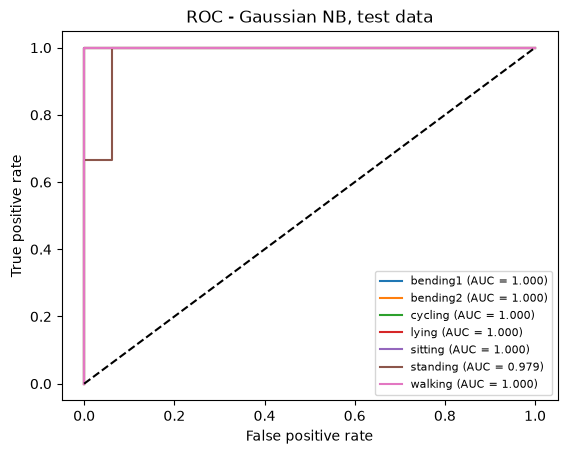

Multinomial NB: best l = 11, CV accuracy = 0.8714
Multinomial NB, test data: accuracy = 0.9474, error = 0.0526, AUC = 0.9911


,pred bending1,pred bending2,pred cycling,pred lying,pred sitting,pred standing,pred walking
true bending1,2,0,0,0,0,0,0
true bending2,0,2,0,0,0,0,0
true cycling,0,0,3,0,0,0,0
true lying,0,0,0,3,0,0,0
true sitting,0,0,0,0,2,1,0
true standing,0,0,0,0,0,3,0
true walking,0,0,0,0,0,0,3


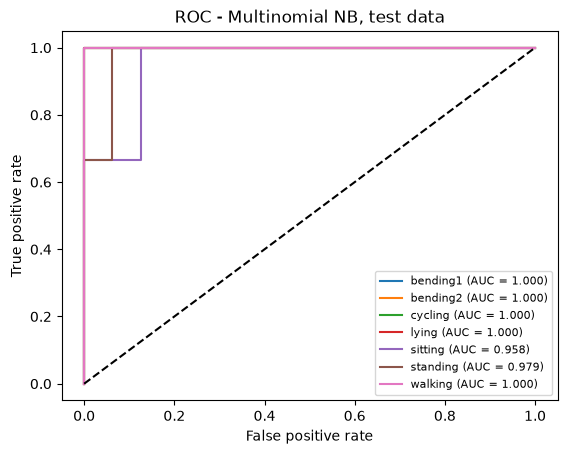

In [108]:
nb_summary = {}
for name, nb_model in [('Gaussian NB', GaussianNB()), ('Multinomial NB', MultinomialNB())]:
    nb_l = int(nb_grid[name].round(6).idxmax())  # idxmax keeps the smallest l on ties
    X_tr, y_tr = xy(features_by_l[nb_l], 'train', target='activity')
    X_te, y_te = xy(features_by_l[nb_l], 'test', target='activity')
    nb_model.fit(X_tr, y_tr)
    print(f'{name}: best l = {nb_l}, CV accuracy = {nb_grid[name][nb_l]:.4f}')
    acc, auc = evaluate(nb_model, X_te, y_te, f'{name}, test data')
    nb_summary[name] = (nb_l, nb_grid[name][nb_l], acc, auc)

**Observations:**
* Gaussian NB: best l = 1, test accuracy 89.47%. Multinomial NB: best l = 11, test accuracy 94.74%.
* Multinomial NB does slightly better on the test set (1 error vs. 2), while Gaussian NB has a slightly higher CV accuracy (88.57% vs. 87.14%), so they perform about the same.

#### iii. Better method

In [110]:
summary = pd.DataFrame(
    [(multi_l, multi_cv_acc, multi_test_acc, multi_test_auc)] + list(nb_summary.values()),
    columns=['Best l', 'CV accuracy', 'Test accuracy', 'Test macro AUC'],
    index=['L1 multinomial regression'] + list(nb_summary.keys()))
summary.insert(3, 'Test error', 1 - summary['Test accuracy'])
display(summary.round(4))

,Best l,CV accuracy,Test accuracy,Test error,Test macro AUC
L1 multinomial regression,1,0.8989,0.9474,0.0526,0.9911
Gaussian NB,1,0.8857,0.8947,0.1053,0.9970
Multinomial NB,11,0.8714,0.9474,0.0526,0.9911


* **L1-penalized multinomial regression is better.** It has the highest CV accuracy (89.89%) and ties for the best test accuracy (94.74%).

## 3. ISLR 4.8.3: QDA with One Feature - the Bayes Classifier Is Quadratic

With one feature and $X \mid Y = k \sim N(\mu_k, \sigma_k^2)$, the posterior probability of class $k$ is

$$p_k(x) = \frac{\pi_k \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)}{\sum_{l=1}^{K} \pi_l \frac{1}{\sqrt{2\pi}\,\sigma_l} \exp\left(-\frac{(x-\mu_l)^2}{2\sigma_l^2}\right)}$$

The denominator is the same for every class, so taking the log of the numerator gives

$$\delta_k(x) = -\frac{1}{2\sigma_k^2}\,x^2 + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} + \log \pi_k - \log \sigma_k$$

Since $\sigma_k$ is different for each class, the $x^2$ term does not cancel when two classes are compared (it only cancels in LDA, where all $\sigma_k$ are equal). So the Bayes classifier is **quadratic in $x$, not linear**.

## 4. ISLR 4.8.7: Probability of Issuing a Dividend (Bayes' Theorem)

Given $\mu_{\text{Yes}} = 10$, $\mu_{\text{No}} = 0$, $\sigma^2 = 36$, $\pi_{\text{Yes}} = 0.8$, $\pi_{\text{No}} = 0.2$ and $x = 4$, by Bayes' theorem (the common factor $\frac{1}{\sqrt{2\pi \cdot 36}}$ cancels):

$$\Pr(\text{Yes} \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.4852}{0.4852 + 0.1601} \approx 0.752$$

**The probability that the company issues a dividend is about 75.2%.**